# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo

- Alumno 1 : Norberto Narvaez
- Alumno 2 :


In [ ]:
import os
import sys
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import insightface
from insightface import model_zoo

print("Python:", sys.version.split()[0])
print("InsightFace:", insightface.__version__)
print("Carpeta actual:", os.getcwd())
print("¿Está el dataset?:", os.path.exists("data/105_classes_pins_dataset"))

Python: 3.12.15
InsightFace: 0.7.3
Carpeta actual: /work
¿Está el dataset?: True


: 

In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data/105_classes_pins_dataset")

filas = []
for carpeta in sorted(DATA_DIR.iterdir()):
    for img in carpeta.iterdir():
        filas.append({"identidad": carpeta.name.replace("pins_", ""), "path": str(img)})

df = pd.DataFrame(filas)
df.head()

,identidad,path
0,Adriana Lima,data/105_classes_pins_dataset/pins_Adriana Lim...
1,Adriana Lima,data/105_classes_pins_dataset/pins_Adriana Lim...
2,Adriana Lima,data/105_classes_pins_dataset/pins_Adriana Lim...
3,Adriana Lima,data/105_classes_pins_dataset/pins_Adriana Lim...
4,Adriana Lima,data/105_classes_pins_dataset/pins_Adriana Lim...


In [ ]:
print("Total de imágenes:", len(df))
print("Total de identidades:", df["identidad"].nunique())

conteo = df["identidad"].value_counts()
conteo.describe()

Total de imágenes: 17499
Total de identidades: 105


count    105.000000
mean     166.657143
std       33.844903
min       86.000000
25%      141.000000
50%      169.000000
75%      191.000000
max      237.000000
Name: count, dtype: float64

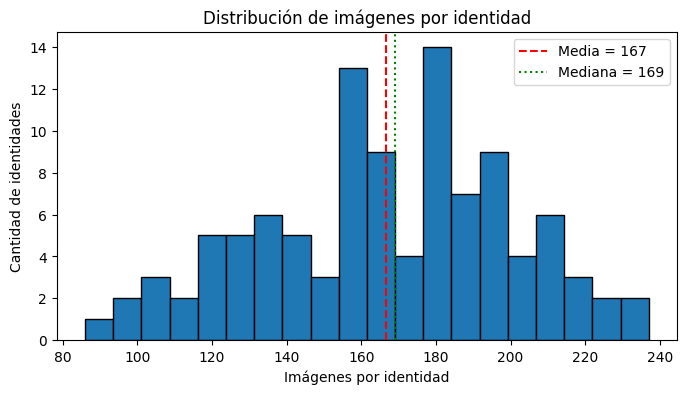

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(conteo, bins=20, edgecolor="black")
ax.axvline(conteo.mean(), color="red", linestyle="--", label=f"Media = {conteo.mean():.0f}")
ax.axvline(conteo.median(), color="green", linestyle=":", label=f"Mediana = {conteo.median():.0f}")
ax.set_xlabel("Imágenes por identidad")
ax.set_ylabel("Cantidad de identidades")
ax.set_title("Distribución de imágenes por identidad")
ax.legend()
plt.show()

Todas las barras arrancan en 86 o más, ninguna persona tiene pocas fotos.
La mayor concentración está entre 155 y 200 fotos por persona.
Media y mediana casi superpuestas: no hay valores extremos que deformen el promedio.
Las colas, entre 86–110 y 220–237, son pocas personas.


In [ ]:
from PIL import Image

anchos, altos, modos, corruptas = [], [], [], []

for p in df["path"]:
    try:
        with Image.open(p) as im:
            anchos.append(im.width)
            altos.append(im.height)
            modos.append(im.mode)
            im.verify()
    except Exception:
        anchos.append(None)
        altos.append(None)
        modos.append(None)
        corruptas.append(p)

df["ancho"] = anchos
df["alto"] = altos
df["modo"] = modos

print("Imágenes corruptas:", len(corruptas))
print(df["modo"].value_counts())
df[["ancho", "alto"]].describe()

Imágenes corruptas: 0
modo
RGB    17499
Name: count, dtype: int64


,ancho,alto
count,17499.000000,17499.000000
mean,211.307046,225.520887
std,101.410659,112.598039
min,80.000000,82.000000
25%,122.000000,129.000000
50%,175.000000,185.000000
75%,253.500000,266.000000
max,564.000000,802.000000


Imágenes con algún lado < 112px: 2625 (15.0%)
count    17499.000000
mean         0.942253
std          0.039377
min          0.570136
25%          0.942222
50%          0.944444
75%          0.945701
max          1.472973
Name: aspecto, dtype: float64


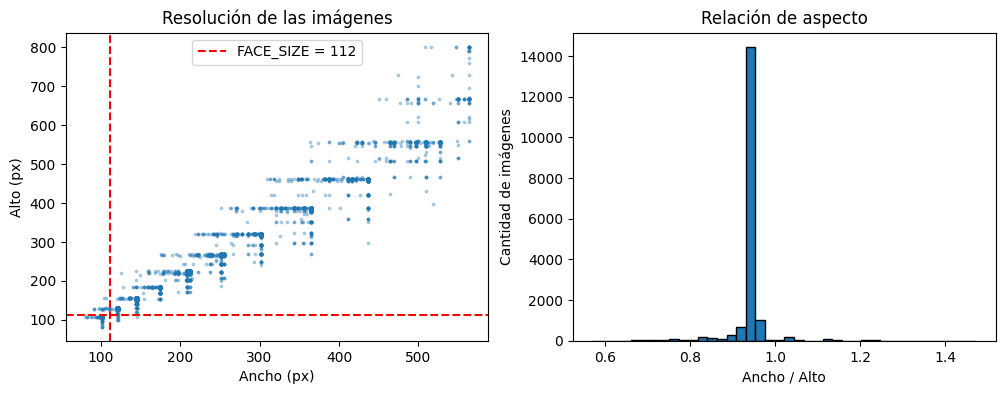

In [ ]:
FACE_SIZE = 112

df["aspecto"] = df["ancho"] / df["alto"]
chicas = df[["ancho", "alto"]].min(axis=1) < FACE_SIZE

print(f"Imágenes con algún lado < {FACE_SIZE}px: {chicas.sum()} ({chicas.mean():.1%})")
print(df["aspecto"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df["ancho"], df["alto"], s=3, alpha=0.3)
axes[0].axvline(FACE_SIZE, color="red", linestyle="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[0].axhline(FACE_SIZE, color="red", linestyle="--")
axes[0].set_xlabel("Ancho (px)")
axes[0].set_ylabel("Alto (px)")
axes[0].set_title("Resolución de las imágenes")
axes[0].legend()

axes[1].hist(df["aspecto"], bins=40, edgecolor="black")
axes[1].set_xlabel("Ancho / Alto")
axes[1].set_ylabel("Cantidad de imágenes")
axes[1].set_title("Relación de aspecto")

plt.show()

### Resoluciones, formato y relación de aspecto

Revisamos las 17.499 imágenes: ninguna está corrupta y todas están en RGB, así que en cuanto a formato el dataset es uniforme y no hubo que descartar nada en este paso.

La resolución varía bastante. La imagen más chica mide 80×82 px, la más grande 564×802 px y la mediana está en 175×185 px. Como la app trabaja con rostros de 112×112 (`FACE_SIZE`), contamos cuántas imágenes tienen algún lado por debajo de ese valor: son 2.625, un 15% del total. Para llevarlas a 112×112 habría que ampliarlas, y eso les agrega borrosidad. Las tenemos en cuenta para el control de calidad, donde vamos a definir un tamaño mínimo de rostro.

En el gráfico de dispersión se ve que ancho y alto crecen juntos, formando una diagonal, y que los tamaños aparecen agrupados en escalones. Esto nos hace pensar que las imágenes se redimensionaron a algunos tamaños estándar cuando se armó el dataset.

La relación de aspecto (ancho/alto) está muy concentrada: la media es 0,942, la mediana 0,944 y el desvío apenas 0,039. Casi todas las imágenes son un poco más altas que anchas, que es la forma típica de un recorte de cara. Hay unos pocos casos extremos, entre 0,57 y 1,47, que vamos a revisar en la grilla de ejemplos.

Esto confirma que las imágenes de Pins ya vienen recortadas alrededor del rostro, por lo que el tamaño de la imagen es aproximadamente el tamaño de la cara. Lo vamos a verificar cuando apliquemos el detector.

Por último, que las imágenes no sean cuadradas no es un problema: no vamos a hacer un resize de la imagen completa a 112×112 (eso deformaría la cara), sino que vamos a detectar el rostro y alinearlo con sus 5 landmarks mediante una transformación de similitud, que rota, escala y traslada sin estirar.


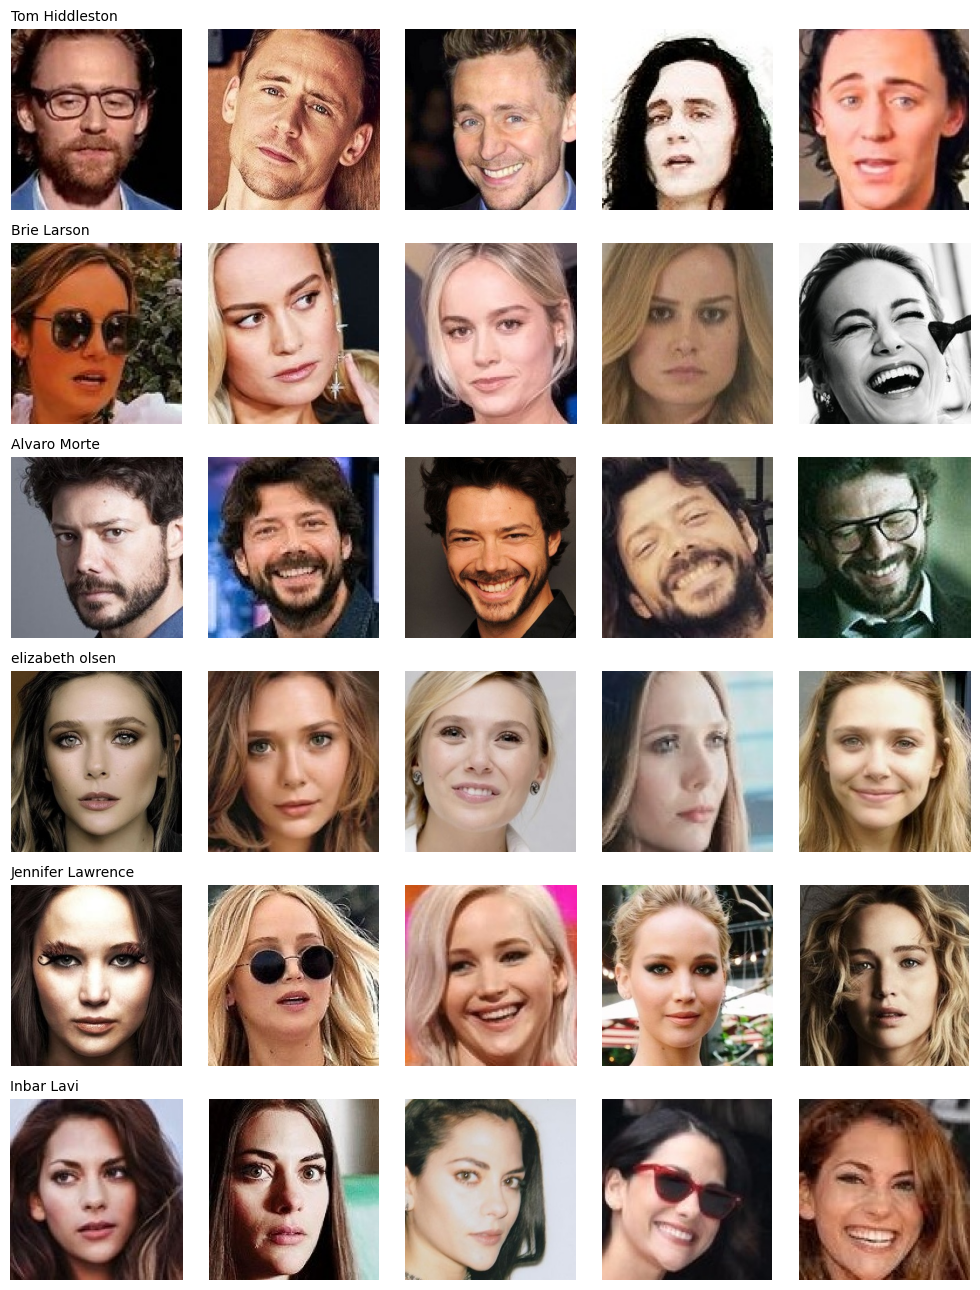

In [ ]:
import random

random.seed(42)
identidades = random.sample(sorted(df["identidad"].unique()), 6)

fig, axes = plt.subplots(6, 5, figsize=(10, 13))
for fila, nombre in enumerate(identidades):
    paths = df[df["identidad"] == nombre]["path"].sample(5, random_state=42)
    for col, p in enumerate(paths):
        axes[fila, col].imshow(Image.open(p))
        axes[fila, col].axis("off")
    axes[fila, 0].set_title(nombre, loc="left", fontsize=10)

plt.tight_layout()
plt.show()

             brillo     contraste
count  17499.000000  17499.000000
mean     112.978809     60.636074
std       30.569173     12.816682
min       14.014952     14.965554
25%       91.606580     52.125164
50%      112.049226     60.719709
75%      133.895486     69.372892
max      221.771274    107.615465


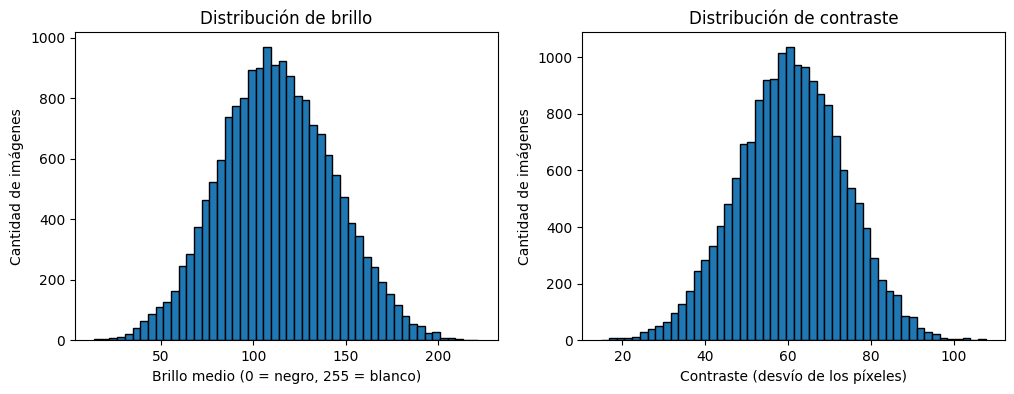

In [ ]:
import numpy as np

brillos, contrastes = [], []

for p in df["path"]:
    gris = np.array(Image.open(p).convert("L"))
    brillos.append(gris.mean())
    contrastes.append(gris.std())

df["brillo"] = brillos
df["contraste"] = contrastes

print(df[["brillo", "contraste"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["brillo"], bins=50, edgecolor="black")
axes[0].set_xlabel("Brillo medio (0 = negro, 255 = blanco)")
axes[0].set_ylabel("Cantidad de imágenes")
axes[0].set_title("Distribución de brillo")

axes[1].hist(df["contraste"], bins=50, edgecolor="black")
axes[1].set_xlabel("Contraste (desvío de los píxeles)")
axes[1].set_ylabel("Cantidad de imágenes")
axes[1].set_title("Distribución de contraste")

plt.show()

Los dos histogramas tienen forma de campana, bastante simétrica:

Brillo: la mayoría entre 70 y 150, con el centro en ~110. No hay montones de fotos casi negras ni casi blancas, y las colas, debajo de 50 o arriba de 180, son pocas fotos.
Contraste: centrado en ~60, la mayoría entre 40 y 80. Las de contraste muy bajo, debajo de 30, son pocas.


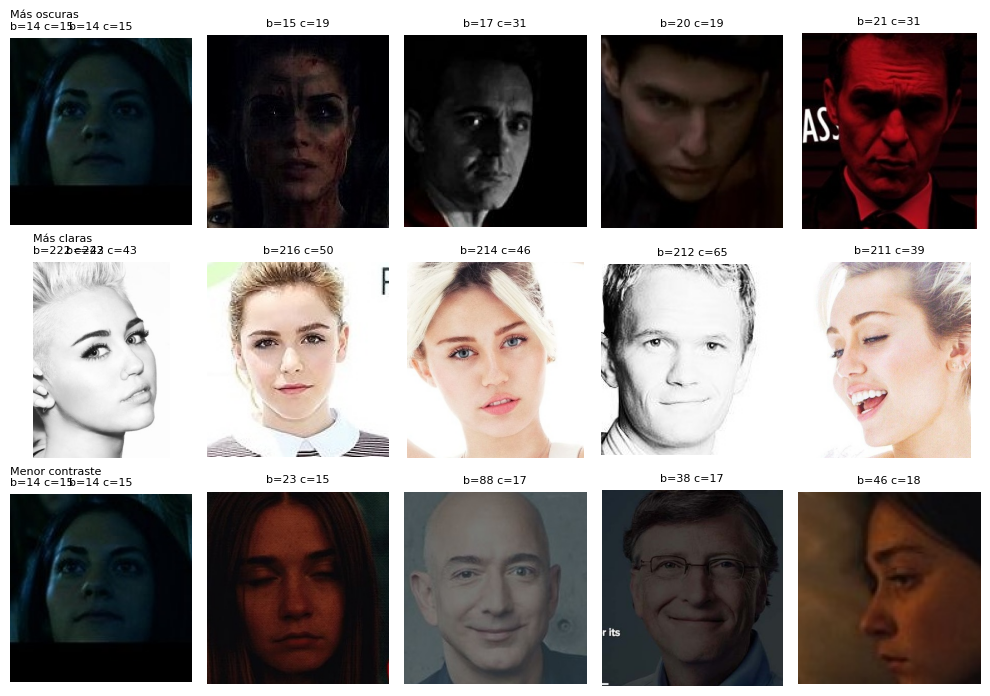

In [ ]:
casos = {
    "Más oscuras": df.nsmallest(5, "brillo"),
    "Más claras": df.nlargest(5, "brillo"),
    "Menor contraste": df.nsmallest(5, "contraste"),
}

fig, axes = plt.subplots(3, 5, figsize=(10, 7))
for fila, (titulo, sub) in enumerate(casos.items()):
    for col, (_, r) in enumerate(sub.iterrows()):
        axes[fila, col].imshow(Image.open(r["path"]))
        axes[fila, col].set_title(f"b={r['brillo']:.0f} c={r['contraste']:.0f}", fontsize=8)
        axes[fila, col].axis("off")
    axes[fila, 0].set_title(f"{titulo}\nb={sub.iloc[0]['brillo']:.0f} c={sub.iloc[0]['contraste']:.0f}", fontsize=8, loc="left")

plt.tight_layout()
plt.show()

### Iluminación: brillo y contraste

Para medir la iluminación pasamos cada imagen a escala de grises y calculamos dos valores: el **brillo** (promedio de los píxeles, de 0 a 255) y el **contraste** (desvío estándar de los píxeles).

Las dos distribuciones tienen forma de campana y son bastante simétricas. El brillo se concentra alrededor de 110 y la mayoría de las imágenes cae entre 70 y 150. El contraste ronda los 60, con la mayoría entre 40 y 80. O sea que la mayor parte del dataset tiene una iluminación razonable.

Las colas de las distribuciones (imágenes muy oscuras, muy claras o con muy poco contraste) son pocas, pero son los casos difíciles para el modelo. Las mostramos en la grilla de casos extremos y las vamos a usar para definir la regla de exposición en el control de calidad.


count    17499.000000
mean      1013.909660
std       1230.636915
min          6.639502
25%        312.707679
50%        641.324280
75%       1240.171277
max      36429.208686
Name: nitidez, dtype: float64


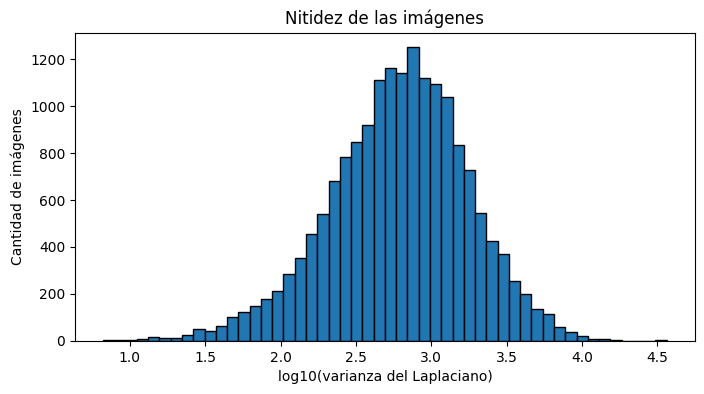

In [ ]:
import cv2

nitidez = []
for p in df["path"]:
    gris = np.array(Image.open(p).convert("L"))
    nitidez.append(cv2.Laplacian(gris, cv2.CV_64F).var())

df["nitidez"] = nitidez
print(df["nitidez"].describe())

plt.figure(figsize=(8, 4))
plt.hist(np.log10(df["nitidez"]), bins=50, edgecolor="black")
plt.xlabel("log10(varianza del Laplaciano)")
plt.ylabel("Cantidad de imágenes")
plt.title("Nitidez de las imágenes")
plt.show()

In [ ]:
def dhash(path, tam=8):
    gris = Image.open(path).convert("L").resize((tam + 1, tam))
    px = np.array(gris)
    bits = px[:, 1:] > px[:, :-1]
    return "".join(bits.flatten().astype(int).astype(str))

df["hash"] = [dhash(p) for p in df["path"]]

dup_exactos = df.duplicated("hash", keep="first")
print("Duplicados exactos (mismo hash):", dup_exactos.sum())

personas_por_hash = df.groupby("hash")["identidad"].nunique()
print("Hashes repetidos entre personas distintas:", (personas_por_hash > 1).sum())


Duplicados exactos (mismo hash): 48
Hashes repetidos entre personas distintas: 0


48 duplicados exactos: son fotos que aparecen más de una vez dentro de la misma persona. Hay que sacarlas, porque si una copia cae en train y la otra en test, el modelo “ya vio” esa foto y la métrica sale inflada. Es la fuga de datos que el TP pide evitar en el 2.7.
0 entre personas distintas: no encontramos la misma foto etiquetada con dos nombres, así que con este método no aparecen errores de etiquetado.


In [ ]:
UMBRAL_HAMMING = 5

casi_dup = pd.Series(False, index=df.index)
pares = []

for nombre, grupo in df.groupby("identidad"):
    bits = np.array([[c == "1" for c in h] for h in grupo["hash"]])
    dist = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)
    idx = grupo.index.to_numpy()
    for i in range(len(idx)):
        for j in range(i):
            if dist[i, j] <= UMBRAL_HAMMING:
                casi_dup[idx[i]] = True
                pares.append((idx[j], idx[i], dist[i, j]))
                break

df["casi_dup"] = casi_dup
print("Casi-duplicados (incluye exactos):", casi_dup.sum())

Casi-duplicados (incluye exactos): 344


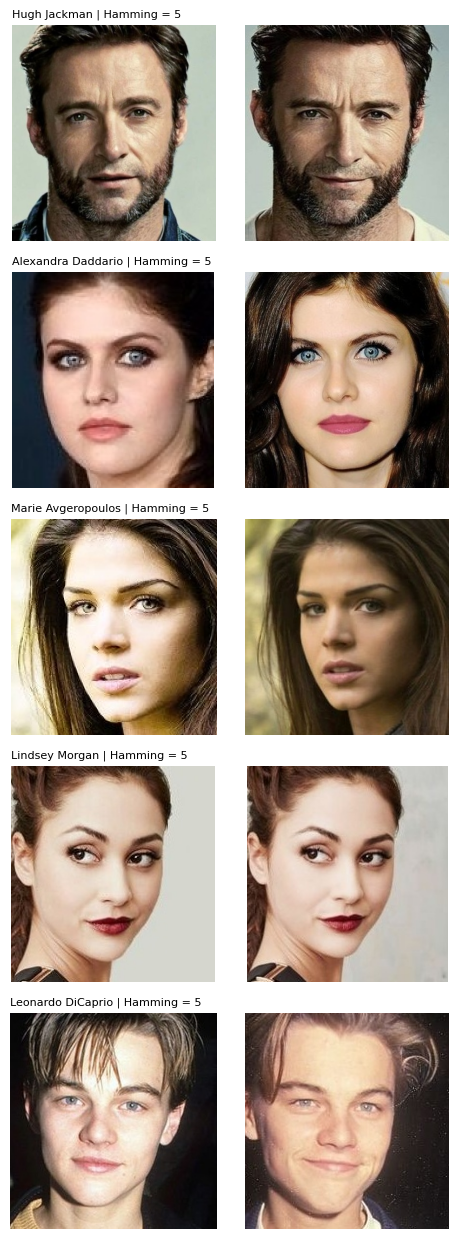

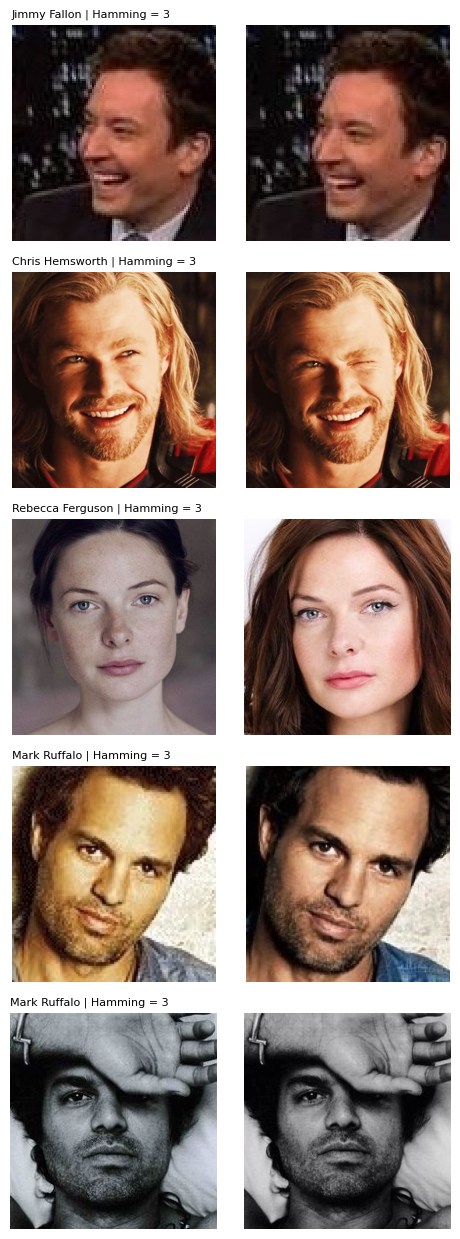

In [ ]:
def ver_pares(distancia, n=5):
    sel = [p for p in pares if p[2] == distancia]
    sel = random.Random(42).sample(sel, min(n, len(sel)))
    fig, axes = plt.subplots(len(sel), 2, figsize=(5, 2.5 * len(sel)))
    for fila, (a, b, d) in enumerate(sel):
        for col, k in enumerate([a, b]):
            axes[fila, col].imshow(Image.open(df.loc[k, "path"]))
            axes[fila, col].axis("off")
        axes[fila, 0].set_title(f"{df.loc[a, 'identidad']} | Hamming = {d}", fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()

ver_pares(5)
ver_pares(3)

In [ ]:
import insightface, sys, os
print("Python:", sys.version.split()[0])
print("InsightFace:", insightface.__version__)
print("Carpeta actual:", os.getcwd())
print("¿Está el dataset?:", os.path.exists("data/105_classes_pins_dataset"))

Python: 3.12.15
InsightFace: 0.7.3
Carpeta actual: /work
¿Está el dataset?: True


2.4 Detección y alineación


In [ ]:
DET_INPUT_SIZE = 640
DET_SCORE_THRESHOLD = 0.5

detector = model_zoo.get_model("models/det_10g.onnx")
detector.prepare(ctx_id=-1, input_size=(DET_INPUT_SIZE, DET_INPUT_SIZE), det_thresh=DET_SCORE_THRESHOLD)

img = cv2.imread(df.loc[0, "path"])
bboxes, kpss = detector.detect(img)

print("Forma de la imagen:", img.shape)
print("Cajas:\n", bboxes)
print("Landmarks:\n", kpss)

/usr/local/lib/python3.12/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:123: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Forma de la imagen: (266, 251, 3)
Cajas:
 []
Landmarks:
 []


Cajas con borde:
 [[151.91267   149.79913   327.64392   365.39838     0.8990054]]


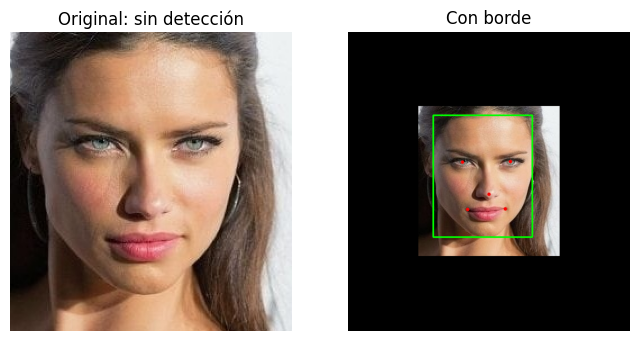

In [ ]:
PAD = 0.5

h, w = img.shape[:2]
img_pad = cv2.copyMakeBorder(img, int(h * PAD), int(h * PAD), int(w * PAD), int(w * PAD),
                             cv2.BORDER_CONSTANT, value=(0, 0, 0))
bboxes_p, kpss_p = detector.detect(img_pad)
print("Cajas con borde:\n", bboxes_p)

vis = img_pad.copy()
for (x1, y1, x2, y2, score), kps in zip(bboxes_p, kpss_p):
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    for x, y in kps:
        cv2.circle(vis, (int(x), int(y)), 3, (0, 0, 255), -1)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original: sin detección")
axes[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("Con borde")
for ax in axes:
    ax.axis("off")
plt.show()

In [ ]:
def detectar(img, pad):
    h, w = img.shape[:2]
    py, px = int(h * pad), int(w * pad)
    img_pad = cv2.copyMakeBorder(img, py, py, px, px, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    bboxes, kpss = detector.detect(img_pad)
    bboxes[:, [0, 2]] -= px
    bboxes[:, [1, 3]] -= py
    kpss[:, :, 0] -= px
    kpss[:, :, 1] -= py
    return bboxes, kpss

In [ ]:
muestra = df.sample(300, random_state=42)

resultados = []
for pad in [0, 0.25, 0.5]:
    n_caras = pd.Series([len(detectar(cv2.imread(p), pad)[0]) for p in muestra["path"]])
    resultados.append({
        "pad": pad,
        "sin cara": (n_caras == 0).sum(),
        "1 cara": (n_caras == 1).sum(),
        "más de 1": (n_caras > 1).sum(),
    })

pd.DataFrame(resultados)

,pad,sin cara,1 cara,más de 1
0,0.00,269,31,0
1,0.25,0,299,1
2,0.50,0,300,0


Usamos el detector **SCRFD** (`det_10g.onnx`, del paquete `buffalo_l` de InsightFace). Lo elegimos porque es el mismo que usa la app, devuelve los 5 landmarks que necesitamos para alinear, y es el detector con el que trabaja el reconocedor ArcFace que vamos a comparar en la Parte 2.

Al probarlo directamente sobre las imágenes, no detectaba la cara en la mayoría de los casos. Nuestra hipótesis fue que, como las imágenes de Pins ya vienen recortadas alrededor de la cara, el rostro ocupa todo el cuadro, mientras que SCRFD está entrenado con fotos donde la cara aparece con contexto alrededor. Para comprobarlo agregamos un borde negro alrededor de cada imagen y comparamos tres tamaños sobre una muestra de 300 imágenes:


Sin borde el detector falla en el 90% de los casos; con un borde del 50% detecta exactamente una cara en todas. Por eso usamos `PAD = 0.5`. Después de detectar, restamos el borde a las coordenadas para que la caja y los landmarks queden referidos a la imagen original.


In [ ]:
from tqdm import tqdm

PAD = 0.5
DETECCIONES = Path("data/detecciones.pkl")
COLUMNAS_DET = ["n_caras", "bbox", "kps", "det_score"]

if DETECCIONES.exists():
    det = pd.read_pickle(DETECCIONES).set_index("path")
    for col in COLUMNAS_DET:
        df[col] = df["path"].map(det[col])
    print("Detecciones cargadas desde", DETECCIONES)
else:
    n_caras, cajas, puntos, scores = [], [], [], []
    for p in tqdm(df["path"]):
        b, k = detectar(cv2.imread(p), PAD)
        n_caras.append(len(b))
        if len(b) == 0:
            cajas.append(None)
            puntos.append(None)
            scores.append(None)
        else:
            i = np.argmax((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))
            cajas.append(b[i, :4])
            puntos.append(k[i])
            scores.append(b[i, 4])
    df["n_caras"] = n_caras
    df["bbox"] = cajas
    df["kps"] = puntos
    df["det_score"] = scores
    df[["path"] + COLUMNAS_DET].to_pickle(DETECCIONES)

print(df["n_caras"].value_counts().sort_index())

Detecciones cargadas desde data/detecciones.pkl
n_caras
1    17423
2       68
3        7
4        1
Name: count, dtype: int64


In [ ]:
MIN_LADO_CARA = 30

df["lado_cara"] = df["bbox"].apply(
    lambda b: min(b[2] - b[0], b[3] - b[1]) if b is not None else np.nan
)

print(df["lado_cara"].describe())
print(f"Rostros con lado < {MIN_LADO_CARA}px:", (df["lado_cara"] < MIN_LADO_CARA).sum())

count    17499.000000
mean       138.301849
std         71.652740
min         44.709625
25%         84.223618
50%        119.159660
75%        175.892174
max        554.203735
Name: lado_cara, dtype: float64
Rostros con lado < 30px: 0


In [ ]:
MIN_LADO_CARA = 30
UMBRAL_NITIDEZ = df["nitidez"].quantile(0.01)
BRILLO_MIN = 40
BRILLO_MAX = 200

reglas_finales = {
    "corrupta": df["ancho"].isna(),
    "sin rostro": df["n_caras"] == 0,
    "más de un rostro": df["n_caras"] > 1,
    f"rostro chico (< {MIN_LADO_CARA} px)": df["lado_cara"] < MIN_LADO_CARA,
    "borrosa": df["nitidez"] < UMBRAL_NITIDEZ,
    "muy oscura": df["brillo"] < BRILLO_MIN,
    "muy clara": df["brillo"] > BRILLO_MAX,
    "duplicada / casi-duplicada": df["casi_dup"],
}

resumen = pd.DataFrame({"descartadas": {k: int(v.sum()) for k, v in reglas_finales.items()}})
df["descartar"] = np.logical_or.reduce(list(reglas_finales.values()))

print(f"Umbral de nitidez: {UMBRAL_NITIDEZ:.1f}")
print(resumen)
print("\nTotal descartadas:", df["descartar"].sum())
print("Quedan:", (~df["descartar"]).sum())

Umbral de nitidez: 37.7
                            descartadas
corrupta                              0
sin rostro                            0
más de un rostro                     76
rostro chico (< 30 px)                0
borrosa                             175
muy oscura                           97
muy clara                            27
duplicada / casi-duplicada          344

Total descartadas: 701
Quedan: 16798


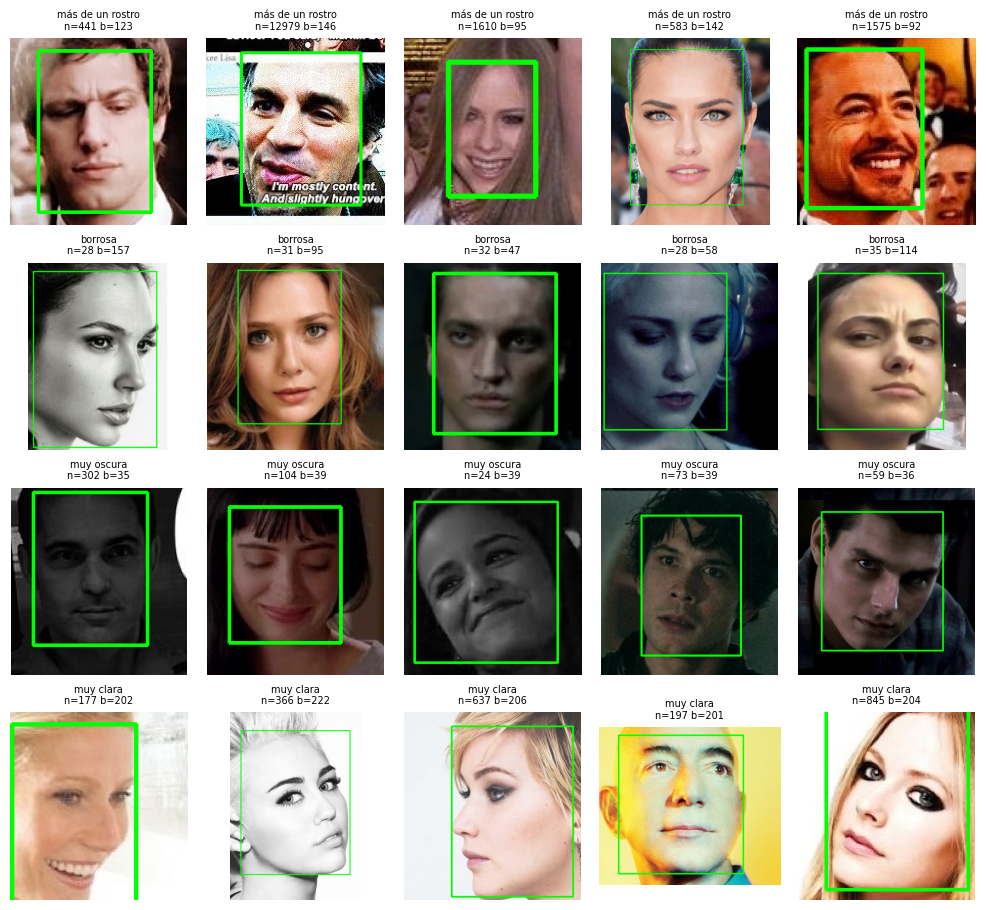

Imágenes por identidad después de limpiar: mín 86 | máx 228


In [ ]:
mostrar = ["más de un rostro", "borrosa", "muy oscura", "muy clara"]

fig, axes = plt.subplots(len(mostrar), 5, figsize=(10, 2.3 * len(mostrar)))
for fila, nombre in enumerate(mostrar):
    mascara = reglas_finales[nombre]
    for col in range(5):
        axes[fila, col].axis("off")
    ejemplos = df[mascara].sample(min(5, mascara.sum()), random_state=42)
    for col, (_, r) in enumerate(ejemplos.iterrows()):
        im = cv2.cvtColor(cv2.imread(r["path"]), cv2.COLOR_BGR2RGB)
        x1, y1, x2, y2 = r["bbox"].astype(int)
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0), 2)
        axes[fila, col].imshow(im)
        axes[fila, col].set_title(f"{nombre}\nn={r['nitidez']:.0f} b={r['brillo']:.0f}", fontsize=7)

plt.tight_layout()
plt.show()

quedan = df[~df["descartar"]]["identidad"].value_counts()
print("Imágenes por identidad después de limpiar: mín", quedan.min(), "| máx", quedan.max())

2.4


/usr/local/lib/python3.12/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


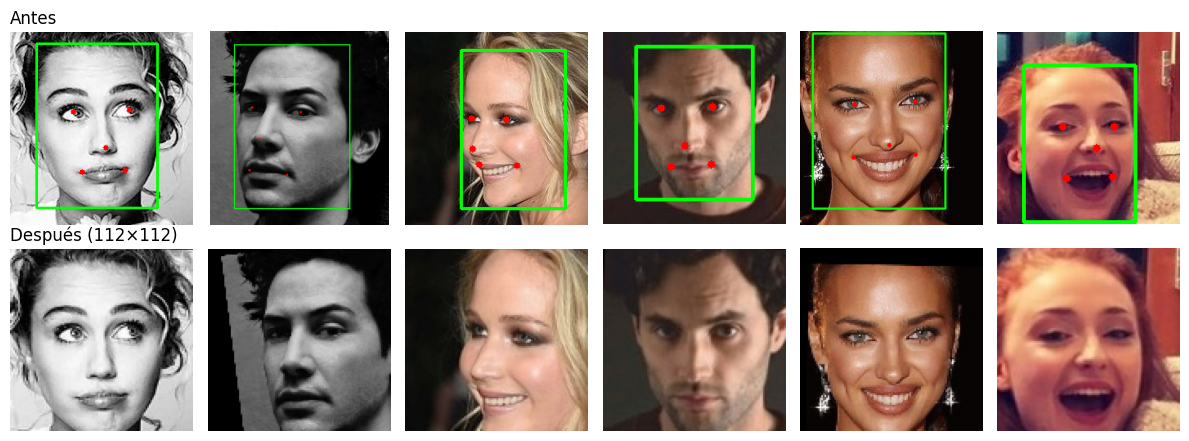

In [ ]:
from insightface.utils import face_align

FACE_SIZE = 112

def alinear(img, kps):
    return face_align.norm_crop(img, landmark=kps, image_size=FACE_SIZE)

ejemplos = df[~df["descartar"]].sample(6, random_state=42)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for col, (_, r) in enumerate(ejemplos.iterrows()):
    img = cv2.imread(r["path"])
    vis = img.copy()
    x1, y1, x2, y2 = r["bbox"].astype(int)
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
    for x, y in r["kps"].astype(int):
        cv2.circle(vis, (x, y), 3, (0, 0, 255), -1)

    alineada = alinear(img, r["kps"])

    axes[0, col].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    axes[1, col].imshow(cv2.cvtColor(alineada, cv2.COLOR_BGR2RGB))
    axes[0, col].axis("off")
    axes[1, col].axis("off")

axes[0, 0].set_title("Antes", loc="left")
axes[1, 0].set_title(f"Después ({FACE_SIZE}×{FACE_SIZE})", loc="left")
plt.tight_layout()
plt.show()

### Alineación

Alineamos cada rostro con `insightface.utils.face_align.norm_crop`, usando los 5 landmarks del detector. La función calcula la transformación de similitud (rotación, escala uniforme y traslación) que lleva los landmarks lo más cerca posible de una plantilla de referencia, la misma con la que se entrenó ArcFace, y recorta el resultado a 112×112. Usamos similitud y no una transformación afín general porque no deforma la cara: conserva sus proporciones, que son lo que identifica a una persona.

En la comparación antes/después se ve que, después de alinear, los ojos quedan horizontales y en la misma posición en todas las imágenes, aunque en la original la cabeza estuviera inclinada.

Observamos dos limitaciones:

- Cuando la cabeza está muy inclinada, enderezarla requiere zona que queda fuera de la imagen original (que en Pins ya viene recortada), y esa zona queda en negro.
- La alineación solo corrige la rotación dentro del plano de la imagen. Las caras de perfil o tres cuartos siguen así, porque girar la cabeza hacia los costados es una rotación en 3D que una transformación 2D no puede deshacer.

Esta misma función de alineación es la que vamos a usar en `face_service.py`, para que el modelo reciba las caras igual en el entrenamiento y en la app.


In [ ]:
ALIGNED_DIR = Path("data/aligned")

rutas_alineadas = []
for _, r in tqdm(df.iterrows(), total=len(df)):
    if r["descartar"]:
        rutas_alineadas.append(None)
        continue
    destino = ALIGNED_DIR / r["identidad"] / (Path(r["path"]).stem + ".png")
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(destino), alinear(cv2.imread(r["path"]), r["kps"]))
    rutas_alineadas.append(str(destino))

df["path_alineada"] = rutas_alineadas
print("Caras alineadas guardadas:", df["path_alineada"].notna().sum())

100%|██████████| 17499/17499 [01:42<00:00, 171.04it/s]

Caras alineadas guardadas: 16798


2.5 Clustering exploratorio


extraer embeddings con un modelo preentrenado sobre las imágenes curadas


In [ ]:
reconocedor = model_zoo.get_model("models/w600k_r50.onnx")
reconocedor.prepare(ctx_id=-1)

EMB_PATH = Path("data/embeddings_arcface.npz")
curadas = df[df["path_alineada"].notna()].reset_index(drop=True)

if EMB_PATH.exists():
    datos = np.load(EMB_PATH)
    pos = {p: i for i, p in enumerate(datos["paths"])}
    emb = datos["emb"][[pos[p] for p in curadas["path_alineada"]]]
    print("Embeddings cargados desde", EMB_PATH)
else:
    lotes = []
    for i in tqdm(range(0, len(curadas), 64)):
        caras = [cv2.imread(p) for p in curadas["path_alineada"][i:i + 64]]
        lotes.append(reconocedor.get_feat(caras))
    emb = np.vstack(lotes)
    emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    np.savez(EMB_PATH, emb=emb, paths=curadas["path_alineada"].to_numpy(dtype=str))

print("Forma de los embeddings:", emb.shape)

/usr/local/lib/python3.12/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:123: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Embeddings cargados desde data/embeddings_arcface.npz
Forma de los embeddings: (16798, 512)


2.5 paso 2: clustering y métricas


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

etiquetas = curadas["identidad"].to_numpy()
n_identidades = curadas["identidad"].nunique()

kmeans = KMeans(n_clusters=n_identidades, n_init=10, random_state=42)
clusters = kmeans.fit_predict(emb)

print("ARI:", round(adjusted_rand_score(etiquetas, clusters), 3))
print("NMI:", round(normalized_mutual_info_score(etiquetas, clusters), 3))
print("Silhouette:", round(silhouette_score(emb, etiquetas, metric="cosine", sample_size=5000, random_state=42), 3))

ARI: 0.974
NMI: 0.994
Silhouette: 0.485


### Clustering con K-Means

Aplicamos K-Means con K = 105 (una por identidad) sobre los embeddings de ArcFace, sin usar las etiquetas, y comparamos los grupos resultantes con las identidades reales:

| Métrica                                   | Valor |
| ----------------------------------------- | ----- |
| ARI                                       | 0,974 |
| NMI                                       | 0,994 |
| Silhouette (con etiquetas reales, coseno) | 0,485 |

ARI y NMI muy cercanos a 1 indican que los grupos que encuentra K-Means coinciden casi perfectamente con las identidades. Esto nos dice dos cosas: que ArcFace separa muy bien a las personas, y que el dataset está bien etiquetado en general. El silhouette de 0,485 indica que las identidades están separadas pero no forman grupos perfectamente compactos, por la variación de pose, iluminación, edad y maquillaje dentro de cada persona.


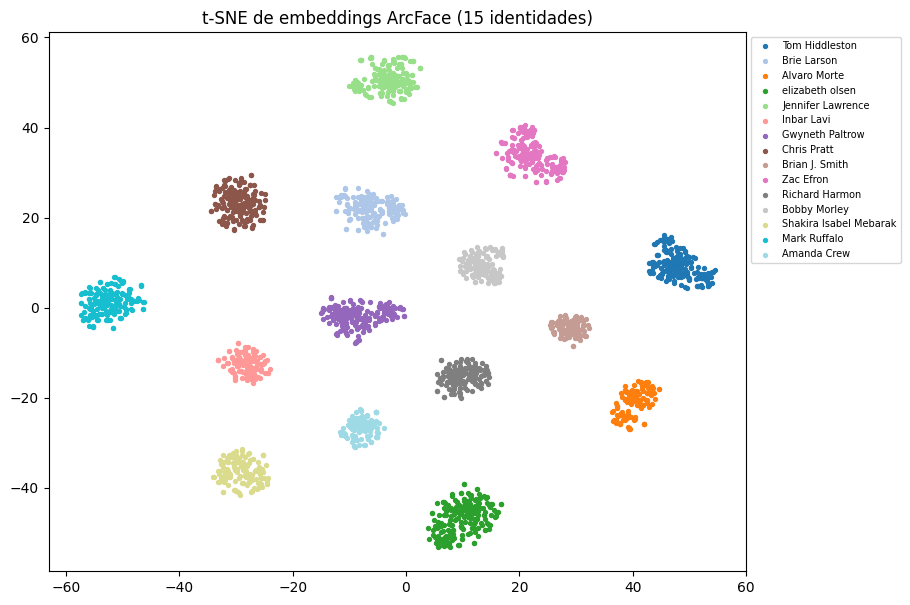

In [ ]:
from sklearn.manifold import TSNE

random.seed(42)
elegidas = random.sample(sorted(curadas["identidad"].unique()), 15)
mask = curadas["identidad"].isin(elegidas).to_numpy()

puntos = TSNE(n_components=2, metric="cosine", random_state=42).fit_transform(emb[mask])
nombres = curadas["identidad"][mask].to_numpy()

plt.figure(figsize=(9, 7))
colores = plt.cm.tab20(np.linspace(0, 1, 15))
for i, nombre in enumerate(elegidas):
    sel = nombres == nombre
    plt.scatter(puntos[sel, 0], puntos[sel, 1], s=8, label=nombre, color=colores[i])
plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.title("t-SNE de embeddings ArcFace (15 identidades)")
plt.show()

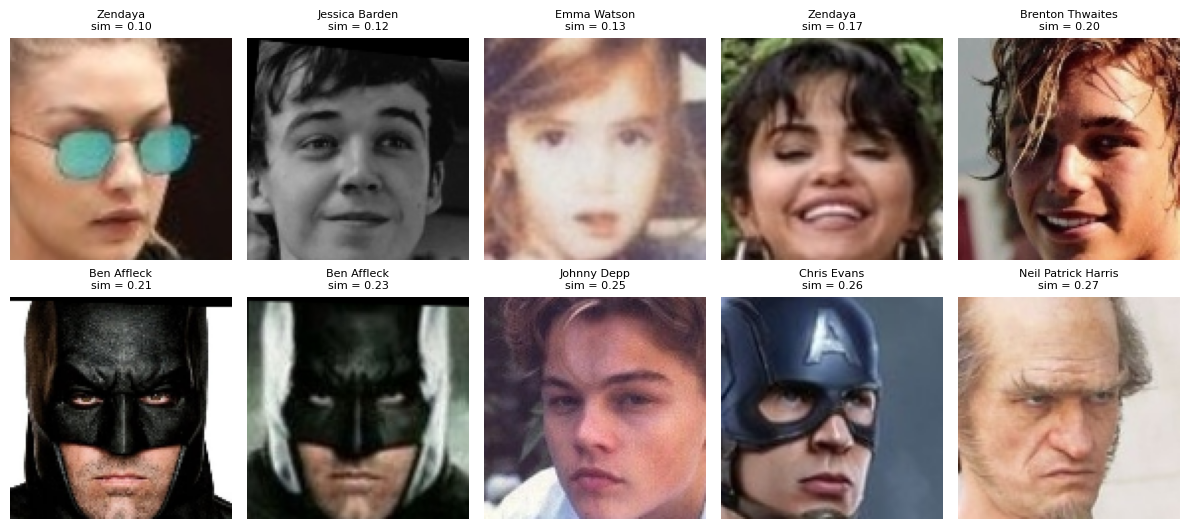

In [ ]:
for nombre in curadas["identidad"].unique():
    sel = (curadas["identidad"] == nombre).to_numpy()
    centro = emb[sel].mean(axis=0)
    centro = centro / np.linalg.norm(centro)
    curadas.loc[sel, "sim_centro"] = emb[sel] @ centro

peores = curadas.nsmallest(10, "sim_centro")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, (_, r) in zip(axes.flat, peores.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r["path_alineada"]), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['identidad']}\nsim = {r['sim_centro']:.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
UMBRAL_OUTLIER = 0.2

mask_ok = (curadas["sim_centro"] >= UMBRAL_OUTLIER).to_numpy()
print("Outliers descartados:", (~mask_ok).sum())

emb = emb[mask_ok]
curadas = curadas[mask_ok].reset_index(drop=True)
print("Caras finales:", len(curadas))

Outliers descartados: 5
Caras finales: 16793


Decidimos **descartar** las caras con similitud menor a 0,2 (5 imágenes: los posibles errores de etiquetado y la foto de la infancia) y **conservar** las de oclusión y maquillaje, porque están bien etiquetadas y son casos difíciles reales que el modelo debería aprender a manejar. El dataset final queda con **16.793 caras alineadas** de 105 identidades.


2.6 Data augmentation


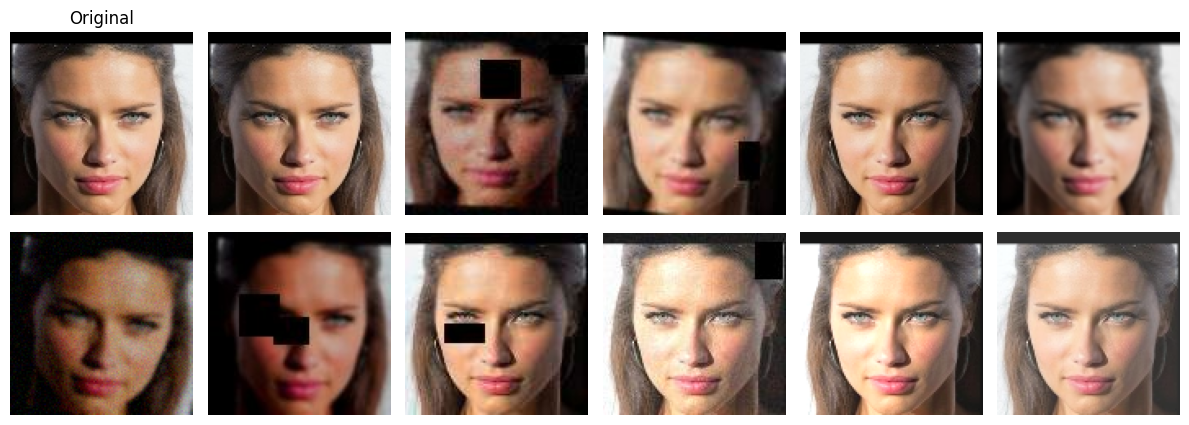

In [ ]:
import albumentations as A

augmentacion = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.GaussNoise(std_range=(0.02, 0.06), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.1, 0.25), hole_width_range=(0.1, 0.25), p=0.3),
    A.ImageCompression(quality_range=(50, 95), p=0.3),
], seed=42)

cara = cv2.cvtColor(cv2.imread(curadas.loc[0, "path_alineada"]), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
axes[0, 0].imshow(cara)
axes[0, 0].set_title("Original")
for ax in axes.flat[1:]:
    ax.imshow(augmentacion(image=cara)["image"])
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Para el augmentation usamos `albumentations`. La idea fue elegir transformaciones que generen variaciones que de verdad podrían aparecer en una foto real, sin cambiar a quién pertenece la cara.

| Transformación                                        | Por qué la usamos                                                                                                          |
| ----------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------- |
| Flip horizontal                                       | Si espejamos una cara, sigue siendo la misma persona.                                                                      |
| Rotación de hasta 10°, y un poco de traslación y zoom | Para simular que la alineación no siempre sale perfecta. Usamos valores chicos porque las caras ya vienen alineadas.       |
| Cambios de brillo y contraste                         | En el EDA vimos que hay fotos con luz muy distinta.                                                                        |
| Cambios leves de color                                | Cada cámara y cada luz cambian un poco los colores. Movimos el tono muy poco para que la piel no quede de un color raro.   |
| Desenfoque                                            | Muchas caras eran chicas y al agrandarlas en la alineación quedaron algo borrosas.                                         |
| Ruido                                                 | Para parecerse a fotos de celular o sacadas con poca luz.                                                                  |
| Rectángulos negros sobre la cara                      | Para simular cosas que tapan parte de la cara, como anteojos, manos o máscaras (como las que aparecieron en los outliers). |
| Compresión JPEG                                       | Las fotos que se suben a la app casi siempre vienen comprimidas.                                                           |

Dejamos afuera el flip vertical y las rotaciones grandes, porque una cara dada vuelta no es algo que vaya a recibir la app. Tampoco usamos deformaciones fuertes, porque cambian las proporciones de la cara, que es justamente lo que permite reconocer a alguien.

En la grilla se ve que algunas versiones quedan bastante degradadas cuando se juntan varias transformaciones a la vez (por ejemplo, desenfoque más ruido), pero la persona se sigue reconociendo. Si al entrenar vemos que es demasiado, la vamos a suavizar.

El augmentation se aplica solamente al conjunto de entrenamiento. Validación y test quedan sin modificar, porque si no estaríamos evaluando con imágenes que no son reales.

No lo usamos para compensar el desbalance de clases, porque el desbalance es chico: después de limpiar, la persona con menos fotos tiene 86. Si en el entrenamiento la CNN tiende a favorecer a las personas con más fotos, lo más simple sería darle más peso a las clases chicas en la loss (_class weights_).


2.7 Splits


In [ ]:
from sklearn.model_selection import train_test_split

random.seed(42)
identidades = sorted(curadas["identidad"].unique())
ids_nuevas = random.sample(identidades, 20)

curadas["split"] = ""
curadas.loc[curadas["identidad"].isin(ids_nuevas), "split"] = "test_open"

conocidas = curadas[curadas["split"] == ""]
train, resto = train_test_split(conocidas, test_size=0.30, stratify=conocidas["identidad"], random_state=42)
val, test = train_test_split(resto, test_size=0.50, stratify=resto["identidad"], random_state=42)

curadas.loc[train.index, "split"] = "train"
curadas.loc[val.index, "split"] = "val"
curadas.loc[test.index, "split"] = "test_closed"

resumen_split = curadas.groupby("split").agg(
    identidades=("identidad", "nunique"),
    imagenes=("identidad", "size"),
)
print(resumen_split)

             identidades  imagenes
split                             
test_closed           85      2054
test_open             20      3105
train                 85      9581
val                   85      2053


In [ ]:
mask_ok = np.ones(len(curadas), dtype=bool)
mask_ok[idx_eval[fugas]] = False

emb = emb[mask_ok]
curadas = curadas[mask_ok].reset_index(drop=True)

print(curadas.groupby("split").agg(identidades=("identidad", "nunique"), imagenes=("identidad", "size")))

curadas[["path_alineada", "identidad", "split"]].to_csv("data/splits.csv", index=False)
print("Splits guardados en data/splits.csv")

             identidades  imagenes
split                             
test_closed           85      1986
test_open             20      3105
train                 85      9581
val                   85      1978
Splits guardados en data/splits.csv


In [ ]:
print("Imágenes repetidas en más de un split:", curadas["path_alineada"].duplicated().sum())

ids_train = set(curadas.loc[curadas["split"] == "train", "identidad"])
ids_open = set(curadas.loc[curadas["split"] == "test_open", "identidad"])
print("Personas de test_open que también están en train:", len(ids_train & ids_open))

es_train = (curadas["split"] == "train").to_numpy()
es_eval = curadas["split"].isin(["val", "test_closed"]).to_numpy()
sim = emb[es_eval] @ emb[es_train].T
print("Imágenes de val/test casi iguales a una de train (sim > 0.95):", (sim.max(axis=1) > 0.95).sum())

Imágenes repetidas en más de un split: 0
Personas de test_open que también están en train: 0
Imágenes de val/test casi iguales a una de train (sim > 0.95): 0


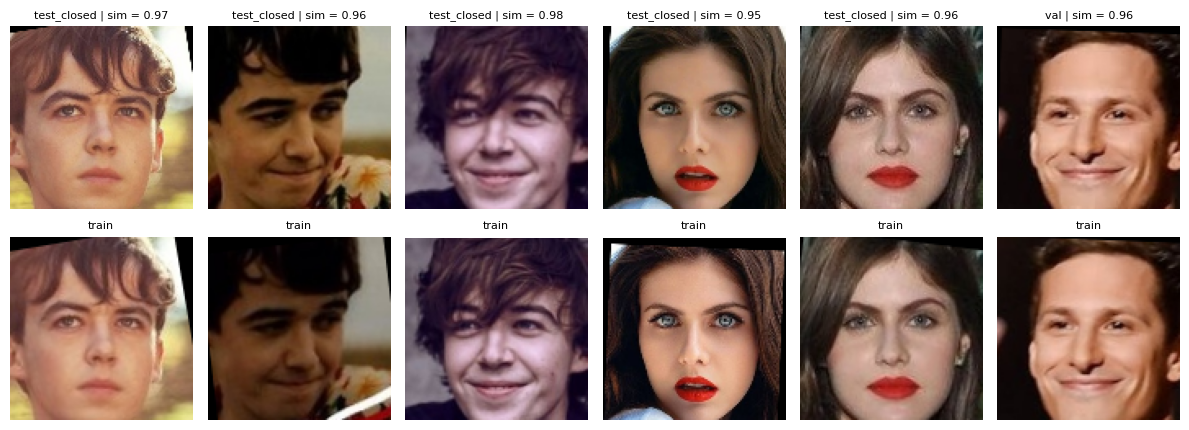

In [ ]:
idx_eval = np.where(es_eval)[0]
idx_train = np.where(es_train)[0]
max_sim = sim.max(axis=1)
mas_parecida = sim.argmax(axis=1)
fugas = np.where(max_sim > 0.95)[0]

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for col, k in enumerate(fugas[:6]):
    a = idx_eval[k]
    b = idx_train[mas_parecida[k]]
    axes[0, col].imshow(cv2.cvtColor(cv2.imread(curadas.loc[a, "path_alineada"]), cv2.COLOR_BGR2RGB))
    axes[1, col].imshow(cv2.cvtColor(cv2.imread(curadas.loc[b, "path_alineada"]), cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{curadas.loc[a, 'split']} | sim = {max_sim[k]:.2f}", fontsize=8)
    axes[1, col].set_title("train", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Separamos los datos pensando en los dos usos que tiene el modelo.

Para el caso **open-set**, que es el real de la app (se registran personas que el modelo nunca vio), elegimos al azar 20 personas y dejamos todas sus fotos aparte, en `test_open`. Ninguna foto de esas personas se usa para entrenar.

Con las otras 85 personas hicimos un split estratificado por identidad: 70% para entrenar, 15% para validación y 15% para test (`test_closed`). Que sea estratificado significa que cada persona tiene más o menos la misma proporción de fotos en cada conjunto. Validación la vamos a usar para elegir hiperparámetros y calibrar el umbral de la app; test solo para reportar las métricas finales.

Para verificar que no hubiera fuga de datos controlamos tres cosas:

- Ninguna imagen aparece en más de un conjunto.
- Ninguna persona de `test_open` aparece en train.
- Comparamos con ArcFace cada cara de validación y test contra todas las de train. Encontramos 143 que tenían una similitud mayor a 0,95 con alguna de train. Al mirarlas, eran la misma foto con un recorte o un color un poco distinto, por eso el dHash no las había detectado. Las sacamos de validación y test.


2.8


## 2.8 Ética, privacidad y licencias

Las caras son datos biométricos: sirven para identificar a una persona, así que hay que tratarlas con más cuidado que otros datos.

**Licencia del dataset.** Usamos Pins Face Recognition, publicado en Kaggle con licencia \_\_\_\_. Las imágenes son fotos de figuras públicas sacadas de Pinterest, así que los derechos de cada foto son de sus autores originales. Las usamos solo con fines académicos y no las redistribuimos: la carpeta `data/` está en el `.gitignore`, así que ni las fotos ni las caras alineadas ni los embeddings se suben al repositorio.

**Licencia del modelo preentrenado.** Los modelos de InsightFace que usamos (el detector SCRFD y el reconocedor ArcFace del paquete `buffalo_l`) solo se pueden usar para investigación o fines no comerciales. Para este trabajo está bien, pero la app no se podría usar comercialmente con estos modelos.

**Fotos propias.** No usamos fotos propias ni de conocidos para el dataset. Si para probar la app registramos caras de personas reales, lo hacemos solo con su consentimiento, y esas fotos tampoco se suben al repositorio.

**Sesgos.** El dataset tiene solo celebridades, en su mayoría actores y modelos jóvenes de países occidentales, con fotos de buena calidad, maquillaje e iluminación profesional. No medimos formalmente la distribución de género, edad o tono de piel, pero a simple vista hay pocas personas mayores y poca diversidad étnica. Esto puede hacer que el modelo funcione peor con grupos que están poco representados y con fotos comunes de celular, que son las que va a recibir la app. El modelo preentrenado también tiene sus propios sesgos, que vienen de los datos con los que fue entrenado.

**Marco legal en Argentina.** La Ley 25.326 de Protección de Datos Personales exige el consentimiento libre, expreso e informado de la persona para tratar sus datos (art. 5), y le da derecho a acceder a ellos, corregirlos o pedir que se borren. La Resolución 4/2019 de la Agencia de Acceso a la Información Pública aclara que los datos biométricos se consideran datos sensibles cuando su uso puede llevar a discriminar a la persona, y en ese caso se les aplica un control más estricto. En nuestra app, los embeddings que se guardan en la base al registrar una identidad son datos biométricos: en un uso real habría que pedir consentimiento, explicar para qué se usan, guardarlos de forma segura y permitir borrarlos.

**Riesgos del reconocimiento facial.** Un falso positivo puede hacer que se confunda a una persona con otra, con consecuencias serias si el sistema se usa para controlar accesos o en seguridad. Además, si el modelo se equivoca más con ciertos grupos, esos errores no se reparten de forma pareja. Y usado sin control, permite vigilar a personas sin que lo sepan. Por eso, en la Parte 2 elegimos el umbral de la app mirando cuántos falsos positivos acepta, y no solo la precisión.
